# Lab 01-04 · Applications of Derivatives

Companion to chapter [01-04](../../chapters/01-04-applications-of-derivatives.md). Handout: [README.md](README.md).

Run the cells in order. Cells marked **🔮 Predict** ask you to write a prediction *before* running.

In [1]:
import math, shutil, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass

## Part 1 — Three optima, and how flat they are

For each, the cell prints the optimum and the penalty for missing it by a factor of 2 either way.

max power (W vs R_L)         optimum x =       50 Ω  value      0.5  at x/2:  -11.1%  at 2x:  -11.1%
repeaters (ps vs n)          optimum x =    6.325  value      253  at x/2:  +25.0%  at 2x:  +25.0%
min energy (pJ vs V)         optimum x =   0.2924 V  value   0.2565  at x/2:  +41.7%  at 2x:  +66.7%


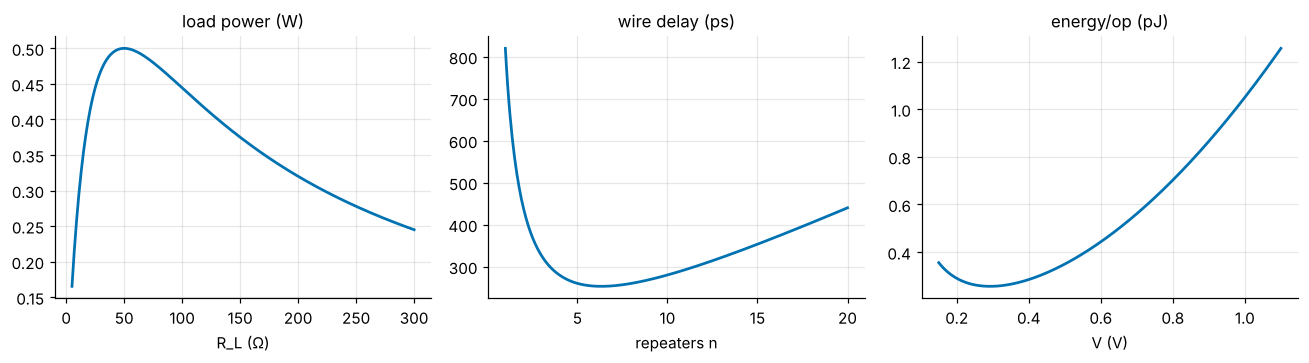

In [2]:
def report(name, f, x_opt, unit=""):
    best = f(x_opt)
    lo, hi = f(x_opt / 2), f(x_opt * 2)
    print(f"{name:<28} optimum x = {x_opt:8.4g}{unit}  value {best:8.4g}  "
          f"at x/2: {100*(lo/best-1):+6.1f}%  at 2x: {100*(hi/best-1):+6.1f}%")

P = lambda RL, Vs=10, Rs=50: Vs**2 * RL / (Rs + RL)**2
report("max power (W vs R_L)", P, 50.0, " Ω")
T = lambda n: 20 * n + 800 / n
report("repeaters (ps vs n)", T, math.sqrt(800 / 20))
A, B = 1.0, 0.05
E = lambda V: A * V**2 + B / V
report("min energy (pJ vs V)", E, (B / (2 * A)) ** (1 / 3), " V")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
r = np.linspace(5, 300, 300); ax[0].plot(r, P(r)); ax[0].set_xlabel("R_L (Ω)"); ax[0].set_title("load power (W)")
n = np.linspace(1, 20, 300); ax[1].plot(n, T(n)); ax[1].set_xlabel("repeaters n"); ax[1].set_title("wire delay (ps)")
V = np.linspace(0.15, 1.1, 300); ax[2].plot(V, E(V)); ax[2].set_xlabel("V (V)"); ax[2].set_title("energy/op (pJ)")
plt.tight_layout(); plt.show()

## Part 2 — Tolerance analysis: worst case, RSS and Monte Carlo

The RC filter of Example 01-04.3: $R$ = 10 kΩ ± 1%, $C$ = 10 nF ± 5%, each uniformly distributed within its tolerance.

**🔮 Predict:** each part is spread *uniformly* across its tolerance. Will the Monte Carlo standard deviation match the worst case (6%), the RSS of the tolerance limits (5.1%), or the RSS of the standard deviations, $\sqrt{(1^2 + 5^2)/3}$ = 2.94% (a uniform ±t spread has σ = t/√3)?

nominal f_c = 1591.5 Hz
worst case (linear)  ±6.00 %   RSS of limits ±5.10 %   RSS of sigmas 2.94 %
Monte Carlo: std 2.95 %, 99.73% interval -5.48 % to +6.09 %


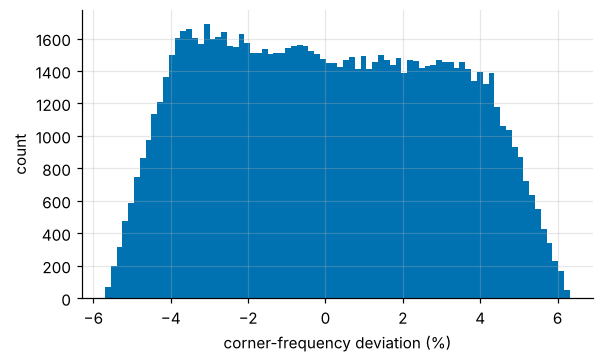

In [3]:
rng = np.random.default_rng(2)
N = 100_000
R = 10e3 * (1 + 0.01 * rng.uniform(-1, 1, N))
Cc = 10e-9 * (1 + 0.05 * rng.uniform(-1, 1, N))
f0 = 1 / (2 * math.pi * 10e3 * 10e-9)
dev = 100 * (1 / (2 * math.pi * R * Cc) / f0 - 1)
print(f"nominal f_c = {f0:.1f} Hz")
print(f"worst case (linear)  ±6.00 %   RSS of limits ±{math.sqrt(1 + 25):.2f} %   RSS of sigmas {math.sqrt((1 + 25) / 3):.2f} %")
print(f"Monte Carlo: std {dev.std():.2f} %, 99.73% interval {np.percentile(dev, 0.135):+.2f} % to {np.percentile(dev, 99.865):+.2f} %")
plt.figure(figsize=(6, 3.4)); plt.hist(dev, bins=80)
plt.xlabel("corner-frequency deviation (%)"); plt.ylabel("count"); plt.show()

The standard deviation matches the RSS of the *standard deviations* (2.94%), not the RSS of the ± limits: RSS needs σ's as inputs. The histogram is nearly flat because one uniform term (the capacitor) dominates, so its extremes approach the worst case. With many comparable independent terms, the distribution would become bell-shaped (the central limit theorem, [03](../../../03-probability-statistics-and-random-variables/README.md)), and the RSS of the σ's would then also fix the probability of landing within any given range.

## Part 3 — Newton versus bisection, and where Newton fails

k = 0: x = 1.000000000000000, error = 4.14e-01
k = 1: x = 1.500000000000000, error = 8.58e-02
k = 2: x = 1.416666666666667, error = 2.45e-03
k = 3: x = 1.414215686274510, error = 2.12e-06
k = 4: x = 1.414213562374690, error = 1.59e-12
k = 5: x = 1.414213562373095, error = 0.00e+00
Newton on arctan converges for |x0| < 1.39


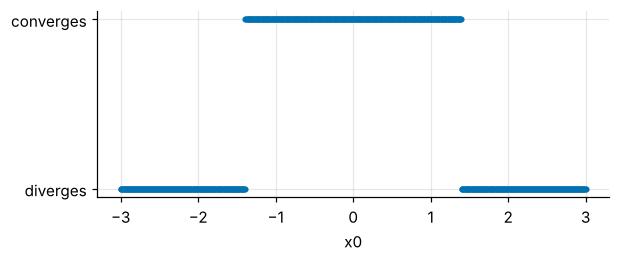

In [4]:
def newton(f, df, x, n):
    xs = [x]
    for _ in range(n):
        x = x - f(x) / df(x); xs.append(x)
    return xs

xs = newton(lambda x: x*x - 2, lambda x: 2*x, 1.0, 5)
for k, x in enumerate(xs):
    print(f"k = {k}: x = {x:.15f}, error = {abs(x - math.sqrt(2)):.2e}")

# basin of convergence for arctan
starts = np.linspace(-3, 3, 601)
final = []
for x0 in starts:
    x = x0
    for _ in range(30):
        x = x - math.atan(x) * (1 + x*x)
        if abs(x) > 1e6: break
    final.append(abs(x) < 1e-8)
final = np.array(final)
print("Newton on arctan converges for |x0| <", starts[final].max().round(3))
plt.figure(figsize=(6, 2.2)); plt.plot(starts, final, "."); plt.xlabel("x0"); plt.yticks([0, 1], ["diverges", "converges"]); plt.show()

## Part 4 — L'Hôpital numerically, and when floating point fights back

Evaluate $h(t) = (e^{-t/\tau_1} - e^{-t/\tau_2})/(\tau_1 - \tau_2)$ at $t = \tau_1 = 1$ ms as $\tau_2 \to \tau_1$, and compare with the limit $1/(e\tau)$.

**🔮 Predict:** at what gap $\tau_2 - \tau_1$ does the direct formula start to lose accuracy?

In [5]:
tau1, t = 1e-3, 1e-3
limit = t / tau1**2 * math.exp(-t / tau1)
for gap in [1e-4, 1e-6, 1e-8, 1e-10, 1e-12, 1e-14]:
    tau2 = tau1 * (1 + gap)
    h = (math.exp(-t/tau1) - math.exp(-t/tau2)) / (tau1 - tau2)
    print(f"relative gap {gap:7.0e}: h = {h:12.6f} 1/s, relative error {abs(h/limit - 1):.1e}")
print(f"limit (L'Hôpital): {limit:.6f} 1/s")

relative gap   1e-04: h =   367.861048 1/s, relative error 5.0e-05
relative gap   1e-06: h =   367.879257 1/s, relative error 5.0e-07
relative gap   1e-08: h =   367.879439 1/s, relative error 4.6e-09
relative gap   1e-10: h =   367.879298 1/s, relative error 3.9e-07
relative gap   1e-12: h =   367.847355 1/s, relative error 8.7e-05
relative gap   1e-14: h =   367.304348 1/s, relative error 1.6e-03
limit (L'Hôpital): 367.879441 1/s


## Part 5 — ngspice confirms maximum power transfer

In [6]:
if shutil.which("ngspice"):
    out = subprocess.run(["ngspice", "-b", "max_power.cir"], capture_output=True, text=True).stdout
    for l in out.splitlines():
        if "=" in l and l.split("=")[0].strip() in ("pmax1", "ropt1", "p100", "pmax2", "ropt2"):
            print("   " + l.strip())
else:
    print("ngspice not found; see SETUP.md. Skipping.")

   pmax1               =  5.000000e-01 at=  5.000000e+01
   ropt1               =  5.000010e+01
   p100                =  4.444444e-01
   pmax1 = 0.5
   ropt1 = 50.0001
   p100 = 0.444444
   pmax2               =  1.250000e-04 at=  2.000000e+03
   ropt2               =  2.000000e+03
   pmax2 = 0.000125
   ropt2 = 2000


## Your turn

1. In Part 1, change the repeater delay from 20 ps to 40 ps. Predict the new optimum count before running.
2. In Part 2, make both tolerances 2%. How does the histogram's shape change, and how do its extremes now compare with the worst case and with ±3 times the RSS of the σ's?